# Peripheral models: would choosing the nearer wall raise their score rate?

Central models beat peripheral models in every tournament so far. Human peripheral players, by contrast, score at about the same rate as human central players. One candidate reason is wall choice. Peripheral models almost always head for High, even when Low is next to their alcove and High is far away.

**Question.** Against a central opponent that always goes High, would a peripheral agent score more per second if it took the nearer wall more often?

This notebook answers it with a geometric race model. Both agents' times come from path length, a fixed speed and a shared start-up delay. Nothing about perception is modelled yet.

**Plan**
1. Inputs measured from the 260929 logs (speed, trigger depth, trial overhead, start-up delay and timing spread).
2. Shortest paths from an alcove back and from the arena centre.
3. Validation of the race model on cases with a known answer.
4. Outcome of each layout when the peripheral agent goes High or Low.
5. Score per second and per trial under each wall-choice policy.
6. Check against the real peripheral-vs-central tournament matchups, and the extra delay that matches them.
7. The value of choosing the nearer wall as the peripheral agent's handicap grows.

**Choices and assumptions**
- Score per second is the primary measure (players are told to maximise score over time). It is total expected score over total expected trial time, including the fixed time between triggers (user's choice). Score per trial is secondary.
- The central opponent always goes High (260929 central p_high 0.998).
- Layouts follow `OctagonArenaSettings.cs`. High is uniform over the 8 walls. Low is 1, 2 or 4 walls away (weights 0.5/0.25/0.25) on a random side. So the peripheral agent's alcove is uniform relative to High (user agreed).
- Both agents share speed, start-up delay and timing spread (section 1). Perception, inference of unseen walls and blocking are ignored until section 6.
- An agent whose body overlaps a lit trigger at slice onset wins that wall at once, whatever it intended (logged: 0.992 of such agents win instantly).
- The peripheral agent waits at the centre of an alcove back. The central agent is placed either at the exact centre ("idealised") or at onset positions sampled from the 260929 central models ("empirical").
- Trials follow the repo convention (first logged trial dropped, incomplete final trial dropped). Agent sims have no spawn trial at the arena centre to drop.

**Modules.** All numbers come from `analysis/analytical_race.py` (tests in `tests/test_analytical_race.py`). Tournament outcomes come from `analysis/tournament_analysis.py`.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import data_strings
import globals
import data_extraction.data_saving as data_saving
import analysis.analytical_race as ar
import analysis.race_estimate as rc
import analysis.tournament_analysis as ta

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)

RECOMPUTE = False                   # rebuild the cached tables
BATCH = '260929'
SIM_DATA_FOLDER = os.path.join(data_strings.SIM_DATA_FOLDER, '2609', BATCH)
SPEED = 10.0                        # units per second (moveSpeed in OctagonAgent.cs, checked in section 1)
N_CENTRAL_POS = 400                 # central onset positions sampled for the empirical opponent
N_RESID = 1500                      # timing residuals kept (all pairs are used)
CUT = 0.5                           # peripheral below this mean onset centrality
rng = np.random.default_rng(0)

# colours: peripheral policies in fixed order, central opponent in grey
C_HIGH, C_NEARER, C_BEST, C_OPP = '#2a78d6', '#eb6834', '#1baf7a', '#6b6b6b'

## 1. Inputs from the logs

**Motivation.** The model needs a speed, a start-up delay, a timing spread and the time each trial costs outside the race. Each is measured from 260929 self-play rather than assumed.

**Method**
1. Split 260929 models into central and peripheral by mean onset centrality (cut 0.5).
2. For five central models, take each trial's onset-to-trigger time, whole trial length, the winner's depth into the alcove at the trigger, and both agents' moving speeds.
3. For every central won trial, take the shortest path from the winner's onset position to the wall it triggered. Start-up delay is the median of (trial time − path / speed). The residual is each trial's remainder.

**Terms**
- `rt_s`: slice onset to trigger, in seconds.
- `overhead_s`: whole trial length less `rt_s`. This is the fixed cost of a trial (trial start to slice onset, trigger to trial end, and the ITI).
- `trigger_p`: the winner's distance from the arena centre along the chosen wall's axis at the trigger. The model's trigger line is `ar.TRIGGER_REACH` (box front 18.857 less body radius 0.61).
- `delay`: start-up delay in seconds, shared by both agents.
- `resid`: per-trial timing residual (s). 0 = exactly on the model. Positive = slower.

**Assumptions**
- The delay and residuals come from won trials only, as a loser's time is not logged. Won trials are the faster ones, so the delay is an underestimate. It is the same for both agents, so it mostly cancels.
- Speed is fixed at the measured value. Any extra time that grows with distance (e.g. turning) goes into the residual. A free regression slope is shown as a check.

In [2]:
# split the batch by mean onset centrality
tables = data_saving.load_data(f'model_characterisation_{BATCH}', data_saving.cache_dir)['result']
centrality = tables['slice'].groupby('model')['centrality'].mean()
PERIPHERAL = sorted(centrality[centrality < CUT].index)
CENTRAL = sorted(centrality[centrality >= CUT].index)
print(f"central {len(CENTRAL)}, peripheral {len(PERIPHERAL)}: {PERIPHERAL}")

# get per-trial timing for five central models
timing_df = data_saving.cached(f'trial_timing_{BATCH}_central5',
                               lambda: ar.collect_trial_timing(SIM_DATA_FOLDER, CENTRAL[:5], verbose=False),
                               recompute=RECOMPUTE, stamp=(tuple(CENTRAL[:5]), 'v2'))
OVERHEAD = timing_df['overhead_s'].mean()

# fit the delay and residuals on central won trials
race_df = data_saving.load_data(f'race_table_{BATCH}', data_saving.cache_dir)['result']
won = race_df[race_df['model'].isin(CENTRAL) & race_df['won'] & (race_df['rt_s'] >= 0.05)]
timing_full, d_won = ar.fit_timing(won, SPEED, OVERHEAD)
slope, intercept = np.polyfit(d_won, won['rt_s'], 1)
timing = ar.Timing(timing_full.delay, SPEED, OVERHEAD, rng.choice(timing_full.resid, N_RESID, replace=False))
exact = ar.Timing(timing.delay, SPEED, OVERHEAD, np.zeros(1))

inputs = pd.Series({
    'moving speed, median (units/s)': timing_df['speed_median'].median(),
    'moving speed, 99th percentile (units/s)': timing_df['speed_p99'].median(),
    'trigger line in model (units)': ar.TRIGGER_REACH,
    'trigger_p, minimum logged (units)': timing_df['trigger_p'].min(),
    'overhead_s, mean': OVERHEAD,
    'overhead_s, sd': timing_df['overhead_s'].std(),
    'central won trials used': len(won),
    'path to triggered wall, 5-95% (units)': f"{np.percentile(d_won, 5):.2f}-{np.percentile(d_won, 95):.2f}",
    'delay (s)': timing.delay,
    'resid sd (s)': timing_full.resid.std(),
    'resid 5 / 50 / 95% (s)': ' / '.join(f"{v:.2f}" for v in np.percentile(timing_full.resid, [5, 50, 95])),
    'free-fit slope (s/unit), check': slope,
    'fixed-speed slope (s/unit)': 1 / SPEED,
})
inputs.to_frame('value')

central 27, peripheral 6: [3, 15, 20, 23, 32, 34]
trial_timing_260929_central5: loaded from cache


,value
"moving speed, median (units/s)",9.999999823
"moving speed, 99th percentile (units/s)",10.000044882
trigger line in model (units),18.247
"trigger_p, minimum logged (units)",18.202605493
"overhead_s, mean",7.092406061
"overhead_s, sd",0.909925337
central won trials used,5344
"path to triggered wall, 5-95% (units)",14.63-20.16
delay (s),0.25568173
resid sd (s),0.425127998


**How to read the table.** Speed and trigger rows check the code values against the logs. The path row shows the range of distances the delay was fitted over. The free-fit slope regresses trial time on path length across those trials. It is shown only as a check against 1 / speed.

## 2. Shortest paths

**Motivation.** A peripheral agent's advantage is distance. Straight lines understate distance from inside an alcove, because the path has to leave through the alcove mouth.

**Method.** Shortest path from a start point to the nearest point of a wall's trigger line, inside the space an agent's centre can reach. Paths may bend only at the 16 alcove mouth corners.

**Terms.** Wall offset is the number of walls from the peripheral agent's own alcove to the target (0 = own alcove, 4 = opposite). Path length is in arena units (wall face to wall face = 33.5).

**How to read the figure.** Left: the reachable space (grey outline), the alcove back where the peripheral agent waits (black square), the centre (black dot), and the shortest path to walls at offsets 1 to 4 (coloured lines, one per offset). Right: path length by wall offset from the alcove back (bars), with the path from the centre to any wall (dashed line).

**Why it is plotted.** A target is reachable before a central agent only where its bar falls below the dashed line. This shows which walls a peripheral agent can win if both agents move equally well.

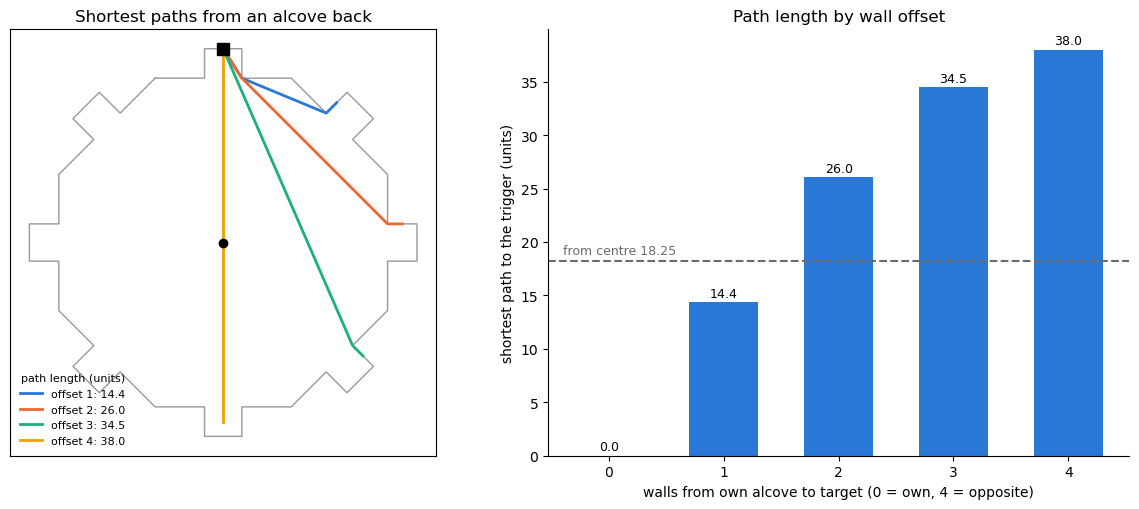

wall offset,0,1,2,3,4
path from alcove back (units),0.0,14.358,26.048,34.495,37.994


In [3]:
# get path lengths from the alcove back of wall row 0, and from the centre
back = ar.alcove_back_positions()[0]
d_back = ar.path_lengths(back[None])[0]
d_centre = ar.path_lengths(np.zeros((1, 2)))[0, 0]
offsets = pd.Series(d_back[[0, 1, 2, 3, 4]], index=pd.Index([0, 1, 2, 3, 4], name='wall offset'))

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw=dict(width_ratios=[1, 1.1]))
ax = axes[0]
poly = np.vstack([ar.reach_polygon(), ar.reach_polygon()[:1]])
ax.plot(poly[:, 0], poly[:, 1], color='#999999', lw=1)
for off, col in zip((1, 2, 3, 4), ('#2a78d6', '#eb6834', '#1baf7a', '#eda100')):
    p = ar.path_points(back, off)
    ax.plot(p[:, 0], p[:, 1], color=col, lw=2, label=f"offset {off}: {d_back[off]:.1f}")
ax.plot(*back, 'ks', ms=8)
ax.plot(0, 0, 'ko', ms=6)
ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
ax.legend(loc='lower left', fontsize=8, frameon=False, title='path length (units)', title_fontsize=8)
ax.set_title('Shortest paths from an alcove back')

ax = axes[1]
ax.bar(offsets.index, offsets.values, color='#2a78d6', width=0.6)
ax.axhline(d_centre, color=C_OPP, ls='--', lw=1.5)
ax.text(-0.4, d_centre + 0.6, f"from centre {d_centre:.2f}", ha='left', color=C_OPP, fontsize=9)
for x, v in offsets.items():
    ax.text(x, v + 0.5, f"{v:.1f}", ha='center', fontsize=9)
ax.set_xlabel('walls from own alcove to target (0 = own, 4 = opposite)')
ax.set_ylabel('shortest path to the trigger (units)')
ax.set_title('Path length by wall offset')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()
offsets.round(3).to_frame('path from alcove back (units)').T

## 3. Validation on known answers

**Motivation.** Before applying the race model, check it on cases whose answer is known by hand.

**Method.** Four checks, each computed by the model and by hand.
- Two agents at the same point tie. Win share = 0.5, with and without timing noise.
- Peripheral at the alcove back, central at the exact centre, no timing noise, always High. The peripheral agent wins its own alcove (High 1/8, Low 1/8, both instant) and an adjacent High unless it stands on Low (2/8 × 3/4). Win share = 7/16 = 0.4375. Score per trial = 1/8 + 0.4/8 + 3/16 = 0.3625.
- Same, nearer wall. This adds an adjacent Low whenever High is 2 or more walls away (probability 5/32). Score per trial = 0.3625 + 0.4 × 5/32 = 0.425.
- With timing noise, the model's win probability and race time for one adjacent-High layout, against 200,000 simulated races.

The same checks (and the path geometry) are unit tests in `tests/test_analytical_race.py`.

In [4]:
centre, periph = np.zeros((1, 2)), ar.alcove_back_positions()
same = ar.build_races(centre, centre)
ideal = ar.build_races(periph, centre)

# simulate one adjacent-High race (High one wall away, Low not under the agent)
row = ideal.index[(ideal['high_off'].abs() == 1) & (ideal['focal_d_low'] > 0)][0]
sim = np.random.default_rng(1)
tf = timing.delay + ideal.loc[row, 'focal_d_high'] / SPEED + sim.choice(timing.resid, 200000)
to = timing.delay + ideal.loc[row, 'opp_d_high'] / SPEED + sim.choice(timing.resid, 200000)
model_row = ar.evaluate(ideal, timing, 'high').loc[row]

checks = pd.DataFrame([
    ('same point, no noise: win share', ar.race_summary(same, exact)['focal_win'], 0.5),
    ('same point, noise: win share', ar.race_summary(same, timing)['focal_win'], 0.5),
    ('always High, no noise: win share', ar.race_summary(ideal, exact, 'high')['focal_win'], 7 / 16),
    ('always High, no noise: score per trial', ar.race_summary(ideal, exact, 'high')['focal_score_trial'], 0.3625),
    ('nearer, no noise: score per trial', ar.race_summary(ideal, exact, 'nearer')['focal_score_trial'], 0.425),
    ('adjacent High, noise: win probability', model_row['focal_win'], (tf < to).mean()),
    ('adjacent High, noise: race time (s)', model_row['race_s'], np.minimum(tf, to).mean()),
], columns=['check', 'model', 'expected']).set_index('check')
checks['difference'] = checks['model'] - checks['expected']
checks.round(4)

,model,expected,difference
check,,,
"same point, no noise: win share",0.5000,0.5000,0.0000
"same point, noise: win share",0.5000,0.5000,0.0000
"always High, no noise: win share",0.4375,0.4375,0.0000
"always High, no noise: score per trial",0.3625,0.3625,0.0000
"nearer, no noise: score per trial",0.4250,0.4250,0.0000
"adjacent High, noise: win probability",0.8964,0.8959,0.0005
"adjacent High, noise: race time (s)",1.7526,1.7527,-0.0001


**How to read the table.** `expected` is the hand count, or the simulated value for the two noise rows. `difference` should be 0 for hand counts and within simulation error (about 0.002) for the simulated rows.

## 4. Outcome of each layout

**Motivation.** Policy differences can only come from layouts where heading High and heading Low give different expected scores. This section lists those layouts.

**Method.** Peripheral agent at the alcove back. Central opponent at the exact centre, always High. Timing noise included. Mirror-image layouts are pooled (High at +1 with Low at +2 joins High at −1 with Low at −2).

**Terms**
- `high_off`, `low_off`: walls from the peripheral agent's alcove to High and to Low (0 = own alcove, sign set so High is at 0 or clockwise).
- `prob`: probability of the layout.
- `win_if_high`, `win_if_low`: peripheral win probability when it heads for High or for Low (0 to 1).
- `score_if_high`, `score_if_low`: expected peripheral score per trial for each choice (win probability × 1.0 or × 0.4).
- `nearer`: the wall with the shorter path. `best`: the choice with the higher expected score.

**How to read the table.** Rows with `best` = Low are the only layouts where turning away from High gains score. The `gain` column is that gain weighted by the layout's probability. Its sum is the most score per trial that wall choice alone can add.

In [5]:
# evaluate both choices for every layout
go_high = ar.evaluate(ideal, timing, 'high')
go_low = ar.evaluate(ideal, timing, np.ones(len(ideal)))
lay = ideal[['high_off', 'low_off', 'prob', 'focal_d_high', 'focal_d_low']].copy()
lay['win_if_high'], lay['score_if_high'] = go_high['focal_win'], go_high['focal_score']
lay['win_if_low'], lay['score_if_low'] = go_low['focal_win'], go_low['focal_score']

# fold mirror images so High sits at 0 or clockwise
flip = (lay['high_off'] < 0) | ((lay['high_off'] == 0) & (lay['low_off'] < 0)) | ((lay['high_off'] == 4) & (lay['low_off'] < 0))
lay.loc[flip, ['high_off', 'low_off']] = -lay.loc[flip, ['high_off', 'low_off']]
lay['low_off'] = ar.signed_offset(lay['low_off'])
lay['high_off'] = ar.signed_offset(lay['high_off'])
by_layout = lay.groupby(['high_off', 'low_off']).agg(
    prob=('prob', 'sum'), path_high=('focal_d_high', 'mean'), path_low=('focal_d_low', 'mean'),
    win_if_high=('win_if_high', 'mean'), win_if_low=('win_if_low', 'mean'),
    score_if_high=('score_if_high', 'mean'), score_if_low=('score_if_low', 'mean'))
by_layout['nearer'] = np.where(by_layout['path_low'] < by_layout['path_high'] - 1e-9, 'Low', 'High')
by_layout['best'] = np.where(by_layout['score_if_low'] > by_layout['score_if_high'], 'Low', 'High')
by_layout['gain'] = by_layout['prob'] * (by_layout[['score_if_high', 'score_if_low']].max(1) - by_layout['score_if_high'])
display(by_layout.round(3))
print(f"layouts where Low is best: probability {by_layout.loc[by_layout.best == 'Low', 'prob'].sum():.4f}, "
      f"score gain per trial {by_layout['gain'].sum():.4f}")
print(f"layouts where Low is nearer but High is best: probability "
      f"{by_layout.loc[(by_layout.nearer == 'Low') & (by_layout.best == 'High'), 'prob'].sum():.4f}")

prob  path_high  path_low  win_if_high  win_if_low  score_if_high  score_if_low nearer  best   gain
high_off low_off                                                                                                      
0         1       0.062      0.000    14.358        1.000       1.000          1.000         1.000   High  High  0.000
          2       0.031      0.000    26.048        1.000       1.000          1.000         1.000   High  High  0.000
          4       0.031      0.000    37.994        1.000       1.000          1.000         1.000   High  High  0.000
1        -3       0.062     14.358    34.495        0.896       0.005          0.896         0.002   High  High  0.000
         -1       0.031     14.358    14.358        0.896       0.896          0.896         0.359   High  High  0.000
          0       0.062     14.358     0.000        1.000       1.000          0.400         0.400    Low  High  0.000
          2       0.062     14.358    26.048        0.896       0.034          0.896         0.014   High  High  0.000
          3       0.031     14.358    34.495        0.896       0.005          0.896         0.002   High  High  0.000
2        -2       0.062     26.048    26.048        0.034       0.034          0.034         0.014   High  High  0.000
          0       0.031     26.048     0.000        1.000       1.000          0.400         0.400    Low  High  0.000
          1       0.062     26.048    14.358        0.034       0.896          0.034         0.359    Low   Low  0.020
          3       0.062     26.048    34.495        0.034       0.005          0.034         0.002   High  High  0.000
          4       0.031     26.048    37.994        0.034       0.005          0.034         0.002   High  High  0.000
3        -3       0.031     34.495    34.495        0.005       0.005          0.005         0.002   High  High  0.000
         -1       0.062     34.495    14.358        0.005       0.896          0.005         0.359    Low   Low  0.022
          1       0.031     34.495    14.358        0.005       0.896          0.005         0.359    Low   Low  0.011
          2       0.062     34.495    26.048        0.005       0.034          0.005         0.014    Low   Low  0.001
          4       0.062     34.495    37.994        0.005       0.005          0.005         0.002   High  High  0.000
4         0       0.031     37.994     0.000        1.000       1.000          0.400         0.400    Low  High  0.000
          2       0.031     37.994    26.048        0.005       0.034          0.005         0.014    Low   Low  0.000
          3       0.062     37.994    34.495        0.005       0.005          0.005         0.002    Low  High  0.000

layouts where Low is best: probability 0.2500, score gain per trial 0.0543
layouts where Low is nearer but High is best: probability 0.1875


## 5. Score under each wall-choice policy

**Motivation.** This answers the question directly. Each policy is scored against the always-High central opponent, and set beside central-vs-central play.

**Method.** Average over all layouts and starting positions, with timing noise.
- Opponent placement: idealised (exact centre) and empirical (400 central onset positions).
- Reference: central vs central, both agents always High.

**Policies (peripheral agent)**
- `high`: always head for High (close to current peripheral models, apart from instant wins).
- `nearer`: head for whichever lit wall has the shorter path.
- `best_trial`: per layout, the choice with the higher expected score per trial.
- `best_rate`: the per-layout choices that maximise score per second over the whole session (found by Dinkelbach iteration). This is the ceiling for wall choice alone.
- q sweep: take Low with probability q when Low is nearer (q = 0 is `high`, q = 1 is `nearer`).

**Terms**
- `focal_score_s`: peripheral score per second over whole trials (primary). `opp_score_s`: the central opponent's.
- `focal_score_s_race`: peripheral score per second of race time only (slice onset to trigger), leaving out the fixed overhead.
- `focal_score_trial`, `opp_score_trial`: score per trial (secondary).
- `focal_win`: peripheral win share. `race_s`: mean onset-to-trigger time. `trial_s`: mean whole trial length.
- `p_go_low`: share of trials in which the peripheral agent heads for Low (instant wins count by their intended wall).

In [6]:
# build the races with the central opponent at the centre and at logged onset positions
cpos = race_df[race_df['model'].isin(CENTRAL)][['x', 'z']].to_numpy(float)
cpos = cpos[rng.choice(len(cpos), N_CENTRAL_POS, replace=False)]
setups = {'idealised': ar.build_races(periph, centre), 'empirical': ar.build_races(periph, cpos)}
refs = {'idealised': ar.build_races(centre, centre), 'empirical': ar.build_races(cpos[:150], cpos[150:300])}

POLICIES = ('high', 'nearer', 'best_trial', 'best_rate')
COLS = ['focal_score_s', 'opp_score_s', 'focal_score_s_race', 'focal_score_trial', 'opp_score_trial', 'focal_win', 'race_s', 'trial_s', 'p_go_low']
rows = []
for name, races in setups.items():
    for pol in POLICIES:
        rows.append(dict(opponent=name, policy=pol, **ar.race_summary(races, timing, pol)))
    rows.append(dict(opponent=name, policy='central vs central', **ar.race_summary(refs[name], timing, 'high')))
policy_table = pd.DataFrame(rows).set_index(['opponent', 'policy'])[COLS]
policy_table.round(4)

focal_score_s  opp_score_s  focal_score_s_race  focal_score_trial  opp_score_trial  focal_win  race_s  trial_s  p_go_low
opponent  policy                                                                                                                                      
idealised high                       0.0407       0.0663              0.2271             0.3522           0.5728     0.4272  1.5505   8.6429    0.0000
          nearer                     0.0474       0.0504              0.2738             0.4063           0.4325     0.5675  1.4839   8.5763    0.4375
          best_trial                 0.0474       0.0504              0.2739             0.4065           0.4326     0.5674  1.4840   8.5764    0.2500
          best_rate                  0.0474       0.0504              0.2739             0.4065           0.4326     0.5674  1.4840   8.5764    0.2500
          central vs central         0.0547       0.0547              0.2439             0.5000           0.5000     0.5000  2.0496   9.1421    0.0000
empirical high                       0.0403       0.0668              0.2245             0.3480           0.5770     0.4230  1.5498   8.6422    0.0000
          nearer                     0.0467       0.0514              0.2701             0.4002           0.4410     0.5590  1.4818   8.5742    0.4375
          best_trial                 0.0467       0.0514              0.2702             0.4004           0.4411     0.5589  1.4819   8.5743    0.2476
          best_rate                  0.0467       0.0514              0.2702             0.4004           0.4411     0.5589  1.4819   8.5743    0.2482
          central vs central         0.0549       0.0550              0.2492             0.4998           0.5002     0.4998  2.0059   9.0983    0.0000

**How to read the table.** Within each opponent placement, compare the four policy rows to each other, and the `focal_score_s` column to the `central vs central` row. In that row "focal" is just one of two central agents.

**How to read the figure.** One line per agent, against q (the probability of taking Low when Low is nearer). Peripheral agent in blue, its central opponent in grey. The dashed line is central-vs-central score. The dotted line is the peripheral `best_rate` ceiling. Left panel: score per second (primary). Right panel: score per trial. Idealised placement, with timing noise.

**Why it is plotted.** If choosing the nearer wall helps, the blue line rises with q. Where it ends relative to the dashed line shows how much of the gap to central play wall choice can close. Where it ends relative to the grey line shows whether the peripheral agent can out-score its opponent head to head.

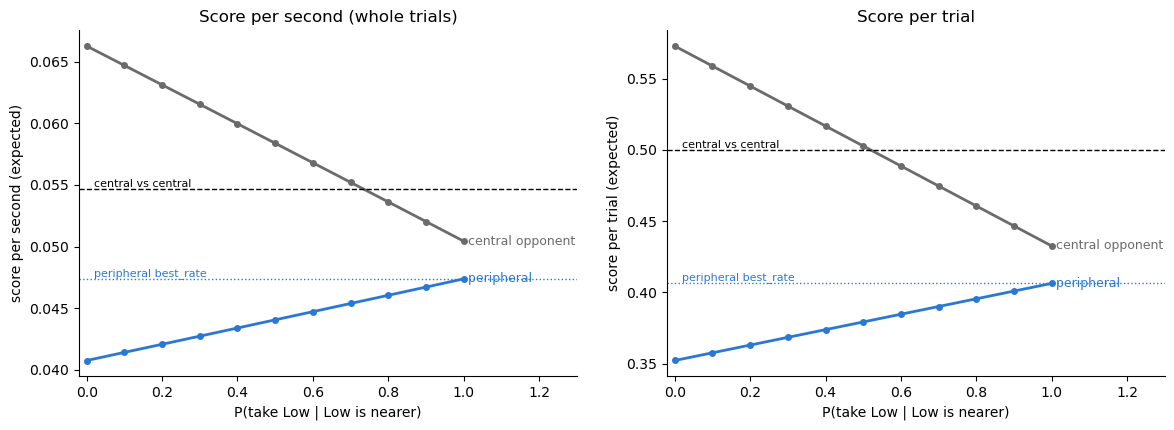

In [7]:
Q = np.linspace(0, 1, 11)
sweep = pd.DataFrame([dict(q=q, **ar.race_summary(setups['idealised'], timing, q)) for q in Q])
ref = policy_table.loc[('idealised', 'central vs central')]
best = policy_table.loc[('idealised', 'best_rate')]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, (f, o, lab) in zip(axes, (('focal_score_s', 'opp_score_s', 'score per second'),
                                  ('focal_score_trial', 'opp_score_trial', 'score per trial'))):
    ax.plot(sweep['q'], sweep[f], color=C_HIGH, lw=2, marker='o', ms=4)
    ax.plot(sweep['q'], sweep[o], color=C_OPP, lw=2, marker='o', ms=4)
    ax.axhline(ref[f], color='black', ls='--', lw=1)
    ax.axhline(best[f], color=C_HIGH, ls=':', lw=1)
    ax.text(0.02, ref[f], 'central vs central', va='bottom', fontsize=8)
    ax.text(0.02, best[f], 'peripheral best_rate', va='bottom', fontsize=8, color=C_HIGH)
    ax.text(1.0, sweep[f].iloc[-1], ' peripheral', va='center', fontsize=9, color=C_HIGH)
    ax.text(1.0, sweep[o].iloc[-1], ' central opponent', va='center', fontsize=9, color=C_OPP)
    ax.set_xlabel('P(take Low | Low is nearer)')
    ax.set_ylabel(f'{lab} (expected)')
    ax.set_xlim(-0.02, 1.3)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_title('Score per second (whole trials)')
axes[1].set_title('Score per trial')
plt.tight_layout(); plt.show()

## 6. Check against the tournaments

**Motivation.** The model assumes a peripheral agent starts and moves as well as a central one. The real peripheral-vs-central tournament matchups show how far that holds.

**Method**
1. Take every peripheral-vs-central pair in the 260715 and 260914-vs-260723 tournaments (13 ordered pairs). Its observed peripheral win share and score per trial come from `ta.perspective_table`.
2. Predict each pair with the race model. Use the peripheral entrant's own onset positions (40 sampled), the central entrant's onset positions (150 sampled), and the central entrant's own p_high. The peripheral agent always heads for High. Timing is the 260929 fit.
3. Add an extra start-up delay to the peripheral agent only, and find the single value (0 to 2 s, step 0.05) that best matches observed win share over all pairs.

**Terms**
- `observed_win`, `observed_score`: real tournament peripheral win share and score per trial.
- `pred_win_geometry`: predicted win share with no extra delay.
- `extra_delay_s`: extra seconds added to every non-instant peripheral time. It stands in for everything the geometry leaves out (slower perception from the alcove, unseen adjacent walls, slower starts, longer paths).

**Assumptions.** Entrant self-play onset positions stand for their tournament positions. The 260929 timing applies to 260715, 260723 and 260914 models (same agent prefab and speed). Entrant positions come from the cached race tables used in the 260929 notebook.

In [8]:
race_entrants = data_saving.load_data('race_tables_tournament_entrants', data_saving.cache_dir)['result']
tournament_trials = data_saving.load_data('tournament_trials_260715_260914', data_saving.cache_dir)['result']
STRATEGY = {('260715', m): 'central' for m in (2, 20, 22)}
STRATEGY.update({('260715', m): 'peripheral' for m in (15, 26, 36)})
STRATEGY.update({('260914', 14): 'central', ('260914', 20): 'central', ('260914', 17): 'peripheral',
                 ('260723', 34): 'central', ('260723', 39): 'central'})


def entrant_batch(tournament, model):
    """ Return the batch an entrant came from. Takes the tournament name and model number. """

    if tournament == '260715':
        return '260715'
    return '260723' if model in (34, 39) else '260914'


# get the observed peripheral-vs-central pairs, and build each pair's races
pairs, pair_races = [], []
for name, trials in tournament_trials.items():
    real = ta.perspective_table(trials).groupby(['focus', 'opp'])[['f_win', 'f_score']].mean()
    for (f, o), r in real.iterrows():
        kf, ko = (entrant_batch(name, f), f), (entrant_batch(name, o), o)
        if STRATEGY.get(kf) != 'peripheral' or STRATEGY.get(ko) != 'central':
            continue
        rf = race_entrants[(race_entrants['batch'] == kf[0]) & (race_entrants['model'] == f)]
        ro = race_entrants[(race_entrants['batch'] == ko[0]) & (race_entrants['model'] == o)]
        fpos = rf[['x', 'z']].to_numpy(float)[rng.choice(len(rf), 40, replace=False)]
        opos = ro[['x', 'z']].to_numpy(float)[rng.choice(len(ro), 150, replace=False)]
        p_opp = ro.loc[ro['won'], 'chose_high'].mean()
        pairs.append(dict(tournament=name, peripheral=f'{kf[0]}_{f}', central=f'{ko[0]}_{o}', opp_p_high=p_opp,
                          peripheral_onset_radius=np.median(np.hypot(rf['x'], rf['z'])),
                          observed_win=r['f_win'], observed_score=r['f_score']))
        pair_races.append(ar.build_races(fpos, opos))
pairs = pd.DataFrame(pairs)

# predict every pair across a grid of extra peripheral delays
GRID = np.round(np.arange(0, 2.01, 0.05), 2)
pred = {x: [ar.race_summary(r, timing, 'high', p, focal_extra_s=x) for r, p in zip(pair_races, pairs['opp_p_high'])]
        for x in GRID}
sse = pd.Series({x: sum((p['focal_win'] - w) ** 2 for p, w in zip(pred[x], pairs['observed_win'])) for x in GRID})
EXTRA = float(sse.idxmin())
pairs['pred_win_geometry'] = [p['focal_win'] for p in pred[0.0]]
pairs['pred_score_geometry'] = [p['focal_score_trial'] for p in pred[0.0]]
pairs['pred_win_fitted'] = [p['focal_win'] for p in pred[EXTRA]]
pairs['pred_score_fitted'] = [p['focal_score_trial'] for p in pred[EXTRA]]
# find each pair's own matching delay
pairs['pair_extra_delay_s'] = [GRID[np.argmin([abs(pred[x][i]['focal_win'] - w) for x in GRID])]
                               for i, w in enumerate(pairs['observed_win'])]
display(pairs.round(3))
summary = pd.Series({
    'pooled extra_delay_s': EXTRA,
    'mean observed win': pairs['observed_win'].mean(),
    'mean predicted win, geometry only': pairs['pred_win_geometry'].mean(),
    'mean predicted win, fitted delay': pairs['pred_win_fitted'].mean(),
    'win MAE, fitted delay': (pairs['pred_win_fitted'] - pairs['observed_win']).abs().mean(),
    'mean observed score per trial': pairs['observed_score'].mean(),
    'mean predicted score per trial, fitted delay': pairs['pred_score_fitted'].mean(),
    'score MAE, fitted delay': (pairs['pred_score_fitted'] - pairs['observed_score']).abs().mean(),
})
summary.round(3).to_frame('value')

,tournament,peripheral,central,opp_p_high,peripheral_onset_radius,observed_win,observed_score,pred_win_geometry,pred_score_geometry,pred_win_fitted,pred_score_fitted,pair_extra_delay_s
0,260715,260715_15,260715_2,0.854,18.811,0.231,0.180,0.406,0.367,0.279,0.239,0.90
1,260715,260715_15,260715_20,0.869,18.811,0.203,0.161,0.410,0.362,0.284,0.236,1.30
2,260715,260715_15,260715_22,0.909,18.811,0.205,0.159,0.408,0.365,0.279,0.236,1.20
3,260715,260715_26,260715_2,0.854,19.585,0.314,0.236,0.416,0.347,0.298,0.229,0.50
4,260715,260715_26,260715_20,0.869,19.585,0.325,0.239,0.409,0.355,0.285,0.231,0.40
5,260715,260715_26,260715_22,0.909,19.585,0.330,0.231,0.411,0.351,0.288,0.228,0.40
6,260715,260715_36,260715_2,0.854,19.413,0.309,0.227,0.412,0.348,0.296,0.233,0.55
7,260715,260715_36,260715_20,0.869,19.413,0.330,0.247,0.414,0.354,0.286,0.226,0.40
8,260715,260715_36,260715_22,0.909,19.413,0.301,0.224,0.416,0.359,0.278,0.222,0.50
9,260914_vs_260723,260914_17,260914_14,1.000,16.970,0.262,0.250,0.378,0.371,0.251,0.244,0.55


,value
pooled extra_delay_s,0.600
mean observed win,0.276
"mean predicted win, geometry only",0.401
"mean predicted win, fitted delay",0.275
"win MAE, fitted delay",0.032
mean observed score per trial,0.223
"mean predicted score per trial, fitted delay",0.235
"score MAE, fitted delay",0.022


**How to read the tables.** One row per ordered tournament pair. `peripheral_onset_radius` is the peripheral entrant's median onset distance from the centre (alcove back = 19.75). `pair_extra_delay_s` is the delay that best matches that pair alone. The summary compares mean predictions with the observed means, and gives the mean absolute error (MAE) at the pooled delay.

## 7. Does the nearer wall still pay with a handicap?

**Motivation.** Section 5 assumes the peripheral agent moves as well as a central one. Section 6 says real peripheral models lose time. Low only wins when the peripheral agent is clearly closer, so a handicap could erase the gain. This section reruns the policy comparison across extra delays.

**Method.** Section 5 setup with the empirical central opponent and timing noise. Add an extra delay of 0 to 1.5 s (step 0.1) to the peripheral agent, and score each policy.

**How to read the figure.** x is the peripheral agent's extra delay (s). Left: peripheral score per second for `high` (blue), `nearer` (orange) and `best_rate` (aqua). The dashed line is central-vs-central. The vertical line marks the delay fitted in section 6. `nearer` and `best_rate` almost coincide, so the orange line is mostly hidden. Right: the gain in peripheral score per second from `nearer` and `best_rate` over `high`, as a percentage of the `high` score. The table below gives the values at selected delays.

**Why it is plotted.** If the gain stays positive at the fitted delay, then taking the nearer wall would still help today's peripheral models. If it vanishes, their timing problem has to be fixed first.

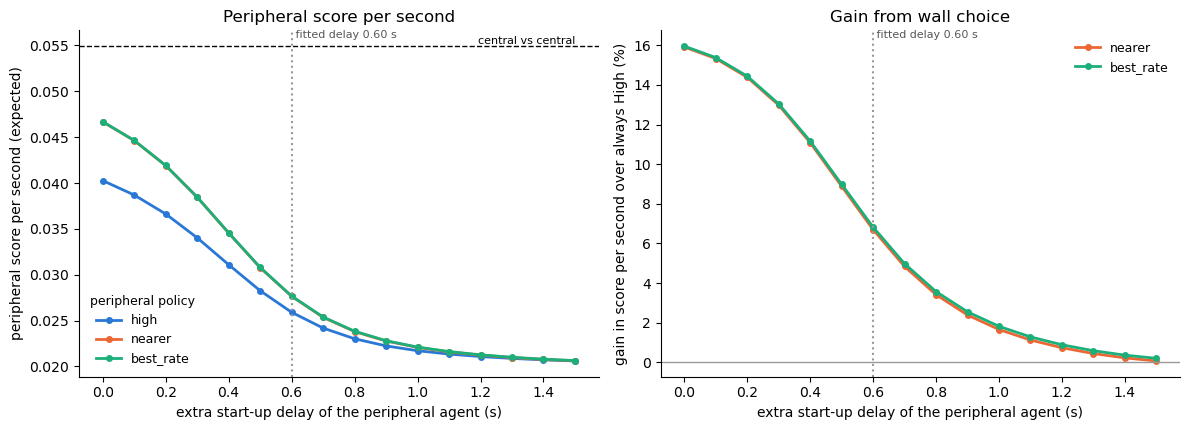

policy,best_rate,high,nearer,nearer gain %,best_rate gain %
extra_s,,,,,
0.0,0.0467,0.0403,0.0467,15.9127,15.9579
0.3,0.0385,0.0340,0.0384,12.9805,13.0427
0.6,0.0277,0.0259,0.0276,6.7027,6.8246
1.0,0.0221,0.0217,0.0221,1.6598,1.8195
1.5,0.0206,0.0206,0.0206,0.0731,0.2069


at extra delay 0.6 s (nearest grid step to the fitted delay):


,focal_score_s,opp_score_s,focal_score_s_race,focal_score_trial,opp_score_trial,focal_win,race_s,trial_s,p_go_low
policy,,,,,,,,,
high,0.0259,0.0803,0.1393,0.2257,0.6993,0.3007,1.6200,8.7124,0.0000
nearer,0.0276,0.0759,0.1496,0.2405,0.6601,0.3399,1.6076,8.7000,0.4375
best_rate,0.0277,0.0759,0.1497,0.2408,0.6603,0.3397,1.6081,8.7005,0.1655


In [9]:
EXTRAS = np.round(np.arange(0, 1.51, 0.1), 2)
emp = setups['empirical']
handicap = pd.DataFrame([dict(extra_s=x, policy=p, **ar.race_summary(emp, timing, p, focal_extra_s=x))
                         for x in EXTRAS for p in ('high', 'nearer', 'best_rate')])
wide = handicap.pivot(index='extra_s', columns='policy', values='focal_score_s')
gain = (wide[['nearer', 'best_rate']].sub(wide['high'], axis=0)).div(wide['high'], axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
for p, c in (('high', C_HIGH), ('nearer', C_NEARER), ('best_rate', C_BEST)):
    ax.plot(wide.index, wide[p], color=c, lw=2, marker='o', ms=4, label=p)
ax.axhline(policy_table.loc[('empirical', 'central vs central'), 'focal_score_s'], color='black', ls='--', lw=1)
ax.text(1.5, policy_table.loc[('empirical', 'central vs central'), 'focal_score_s'], 'central vs central',
        ha='right', va='bottom', fontsize=8)
ax.set_ylabel('peripheral score per second (expected)')
ax.legend(frameon=False, fontsize=9, title='peripheral policy', title_fontsize=9)
ax = axes[1]
for p, c in (('nearer', C_NEARER), ('best_rate', C_BEST)):
    ax.plot(gain.index, gain[p], color=c, lw=2, marker='o', ms=4, label=p)
ax.axhline(0, color='#999999', lw=1)
ax.set_ylabel('gain in score per second over always High (%)')
ax.legend(frameon=False, fontsize=9)
for ax in axes:
    ax.axvline(EXTRA, color='#999999', ls=':', lw=1.5)
    ax.text(EXTRA, ax.get_ylim()[1], f' fitted delay {EXTRA:.2f} s', va='top', fontsize=8, color='#555555')
    ax.set_xlabel('extra start-up delay of the peripheral agent (s)')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_title('Peripheral score per second')
axes[1].set_title('Gain from wall choice')
plt.tight_layout(); plt.show()

at_fit = handicap[np.isclose(handicap['extra_s'], np.round(EXTRA, 1))].set_index('policy')[COLS]
display(pd.concat([wide, gain.add_suffix(' gain %')], axis=1).loc[[0.0, 0.3, 0.6, 1.0, 1.5]].round(4))
print(f"at extra delay {np.round(EXTRA, 1)} s (nearest grid step to the fitted delay):")
at_fit.round(4)

## Interpretation

**Inputs and checks**
- Logged moving speed is 10.0 units/s (median and 99th percentile), matching `moveSpeed`. The lowest logged trigger depth is 18.20 against the model's 18.25. That 0.05 difference is within one frame of movement (0.2 units at 50 Hz).
- The free-fit slope of time on path (0.170 s/unit) is steeper than 1 / speed (0.100). Central won trials cover only 14.6-20.2 units of path, so the slope is poorly pinned. It is kept as a check, not used. A steeper slope would favour the peripheral agent at adjacent walls (larger time gap per unit), so the fixed speed is the cautious choice for the question asked.
- All seven known-answer checks match: hand counts exactly, simulated rows within 0.0005.

**Where wall choice can matter**
- From an alcove back, the adjacent wall is 14.36 units away. That is shorter than the 18.25 from the centre. Every other wall is 26.05 or more. With equal timing, a peripheral agent wins its own alcove (instantly) and the adjacent ones (win probability 0.896 with noise), and almost nothing else (0.034 at 2 walls).
- Going Low beats going High only when Low is adjacent and High is 2 or more walls away. These layouts have total probability 0.25 and add at most 0.054 score per trial. In another 0.1875 of layouts Low is nearer but the choice changes nothing (instant wins, or both walls out of reach).

**Policy result, equal timing (section 5)**
- Taking the nearer wall raises peripheral score per second from 0.0407 to 0.0474 (idealised opponent, +16%) and from 0.0403 to 0.0467 (empirical opponent). `best_rate` gives the same 0.0474 and 0.0467. So the simple nearer-wall rule captures essentially all the gain available from wall choice.
- Score per trial moves the same way: 0.352 to 0.406 (idealised).
- The central opponent drops from 0.0663 to 0.0504 per second. Even so, the peripheral agent stays below central-vs-central play (0.0474 vs 0.0547, 87%). It also stays below its own opponent (0.0474 vs 0.0504).
- The fixed overhead decides this comparison. Counting race time only (`focal_score_s_race`), the nearer-wall peripheral agent scores 0.274 per second, above central-vs-central (0.244). Peripheral wins are short, but every trial also costs 7.09 s of overhead, which dilutes that advantage.

**Tournament check (section 6)**
- With equal timing, the model overrates peripheral entrants. It predicts a mean win share of 0.401 against an observed 0.276. A single extra peripheral delay of 0.60 s matches win share (MAE 0.032) and score per trial (0.223 observed vs 0.235 predicted, MAE 0.022).
- The per-pair delays range from 0.40 to 1.30 s. The largest (0.90-1.30 s) belong to 260715_15, which waits nearer the alcove mouth (median onset radius 18.81).

**Policy result with the fitted handicap (section 7)**
- At 0.6 s extra delay, the nearer wall raises peripheral score per second from 0.0259 to 0.0276 (+6.7%). The central opponent scores 0.0759-0.0803 per second, and central-vs-central is 0.0549.
- The handicap costs far more than wall choice can return. Going from 0 to 0.6 s drops the always-High score from 0.0403 to 0.0259 (-36%).
- The gain from wall choice shrinks as the handicap grows. Adjacent Low only wins while the peripheral agent's 0.39 s distance lead survives the delay.

**Answer.** Yes, choosing the nearer wall would raise peripheral score rate against a central opponent. The gain is modest: about +16% if peripheral agents moved as well as central ones, and about +7% at the handicap today's peripheral models show. It does not close the gap to central play in either case. The larger loss is the 0.6 s the geometry does not explain.

**Limits**
- The 0.6 s handicap is one lump standing for everything left out (perception from the alcove, unseen adjacent walls, slow starts, path inefficiency). It was fitted on 260715 and 260914 entrants, not 260929 models.
- Timing comes from central won trials only, so the shared delay is an underestimate and the spread may be narrow.
- The agent overhead (ITI and trial start/end delays) was set to match the human task, so the 7.09 s overhead applies to humans too. Human movement speed and start-up timing were not measured here, so these numbers do not yet explain why human peripheral players keep pace.